## 1. Kütüphaneler

In [256]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Veri Önişleme

### 2.1 Yüklenme ve İlk İnceleme

In [257]:
df = pd.read_csv("netflix_titles.csv")

In [258]:
df.shape

(8807, 12)

In [259]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


### 2.2 Eksik Değer İşleme

In [260]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [261]:
for i in df.columns:
    null_rate = df[i].isna().sum() / len(df) * 100
    if null_rate > 0 :
        print("{} null rate: {}%".format(i,round(null_rate,2)))

director null rate: 29.91%
cast null rate: 9.37%
country null rate: 9.44%
date_added null rate: 0.11%
rating null rate: 0.05%
duration null rate: 0.03%


In [262]:
df.nunique()

show_id         8807
type               2
title           8807
director        4528
cast            7692
country          748
date_added      1767
release_year      74
rating            17
duration         220
listed_in        514
description     8775
dtype: int64

In [263]:
for i in df.columns:
    nunique_rate = df[i].nunique() / len(df) * 100
    if nunique_rate > 0 :
        print("{} nunique_rate: {}%".format(i,round(nunique_rate,2)))

show_id nunique_rate: 100.0%
type nunique_rate: 0.02%
title nunique_rate: 100.0%
director nunique_rate: 51.41%
cast nunique_rate: 87.34%
country nunique_rate: 8.49%
date_added nunique_rate: 20.06%
release_year nunique_rate: 0.84%
rating nunique_rate: 0.19%
duration nunique_rate: 2.5%
listed_in nunique_rate: 5.84%
description nunique_rate: 99.64%


In [264]:
df.dtypes

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

In [265]:
df['director']=df['director'].fillna('Unknown')
df['cast']=df['cast'].fillna('Unknown')
df['country']=df['country'].fillna('Unknown')

In [266]:
df["date_added"] = pd.to_datetime(df["date_added"], dayfirst=True, errors="coerce")
df['yil']=df['date_added'].dt.year
df['ay']=df['date_added'].dt.month

In [267]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,yil,ay
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,9.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,9.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,9.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,9.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,9.0


In [268]:
df.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           4
duration         3
listed_in        0
description      0
yil             98
ay              98
dtype: int64

In [269]:
df['sure']= df['duration'].str.extract('(\d+)').fillna(0).astype(int)

<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
C:\Users\afay1\AppData\Local\Temp\ipykernel_17028\2823679957.py:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  df['sure']= df['duration'].str.extract('(\d+)').fillna(0).astype(int)
C:\Users\afay1\AppData\Local\Temp\ipykernel_17028\2823679957.py:1: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df['sure']= df['duration'].str.extract('(\d+)').fillna(0).astype(int)


In [270]:
df.sure.head

<bound method NDFrame.head of 0        90
1         2
2         1
3         1
4         2
       ... 
8802    158
8803      2
8804     88
8805     88
8806    111
Name: sure, Length: 8807, dtype: int64>

### 2.3 Metin Temizleme

In [271]:
df.listed_in.head()

0                                        Documentaries
1      International TV Shows, TV Dramas, TV Mysteries
2    Crime TV Shows, International TV Shows, TV Act...
3                               Docuseries, Reality TV
4    International TV Shows, Romantic TV Shows, TV ...
Name: listed_in, dtype: str

In [272]:
df.description.head()

0    As her father nears the end of his life, filmm...
1    After crossing paths at a party, a Cape Town t...
2    To protect his family from a powerful drug lor...
3    Feuds, flirtations and toilet talk go down amo...
4    In a city of coaching centers known to train I...
Name: description, dtype: str

In [273]:
df['listed_in']=df['listed_in'].str.lower()
df['description']=df['description'].str.lower()
df.listed_in.head()
#df.description.head()

0                                        documentaries
1      international tv shows, tv dramas, tv mysteries
2    crime tv shows, international tv shows, tv act...
3                               docuseries, reality tv
4    international tv shows, romantic tv shows, tv ...
Name: listed_in, dtype: str

In [274]:
df["turler_list"]=df["listed_in"].str.split(", ")

In [275]:
df["turler_list"].head()

0                                      [documentaries]
1    [international tv shows, tv dramas, tv mysteries]
2    [crime tv shows, international tv shows, tv ac...
3                             [docuseries, reality tv]
4    [international tv shows, romantic tv shows, tv...
Name: turler_list, dtype: object

## 3. Keşifsel Veri Analizi (EDA)

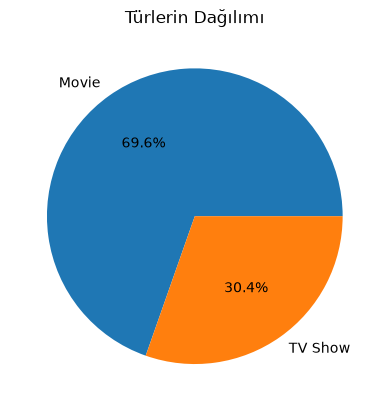

In [276]:
tip=df['type']
tip.value_counts().plot.pie(autopct='%1.1f%%',ylabel="")
plt.title("Türlerin Dağılımı")
plt.show()

<Axes: xlabel='yil', ylabel='count'>

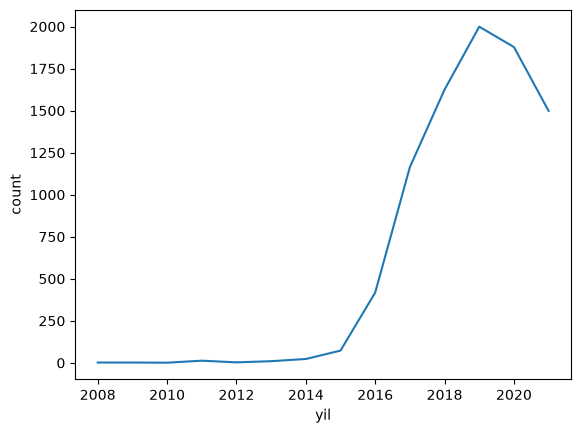

In [277]:
yil_top=df['yil'].value_counts()
sns.lineplot(yil_top)

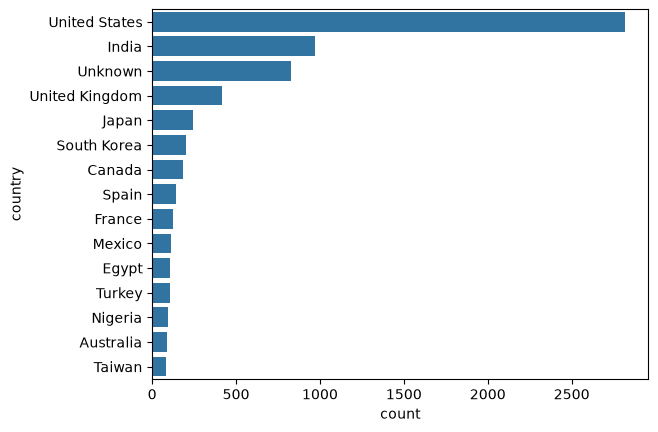

In [304]:
top_countries=df['country'].value_counts().head(15)
sns.barplot(top_countries,orient='h')
plt.savefig("top_countries.png", dpi=300, bbox_inches="tight")

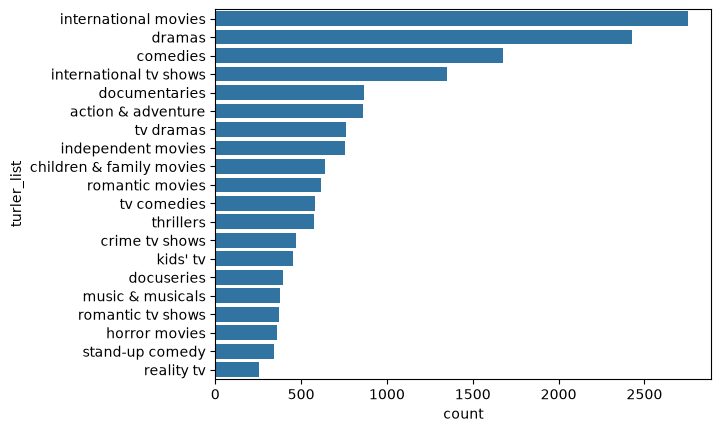

In [302]:
tur_sayılar=(df['turler_list'].explode().dropna().value_counts().head(20))
sns.barplot(tur_sayılar,orient='h')
plt.savefig("genre_distribution.png", dpi=300, bbox_inches="tight")

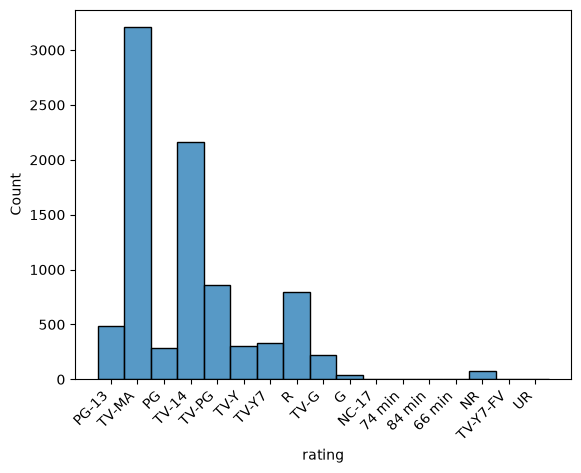

In [282]:
sns.histplot(df["rating"])
plt.xticks(rotation=45, ha="right")
plt.show()

### **Dip Not**: 74 min, 83 min ve 66 min gibi yanlış girilen veriler vardır!!!

In [283]:
gecerli_ratingler = [
    'TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13',
    'TV-Y7', 'TV-Y', 'PG', 'TV-G', 'NR', 'G', 'NC-17', 'UR', 'TV-Y7-FV'
]

df = df[df['rating'].isin(gecerli_ratingler)]

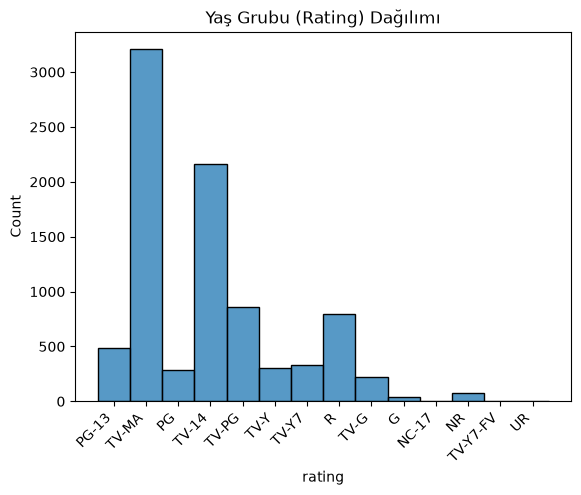

In [284]:
sns.histplot(df["rating"].dropna())
plt.xticks(rotation=45, ha="right")
plt.title("Yaş Grubu (Rating) Dağılımı")
plt.show()

##### Şimdi daha doğru bir grafik oldu

In [285]:
oyuncular_serisi = df["cast"].explode().dropna().str.strip()
yonetmenler_serisi = df["director"].dropna().str.split(",").explode().str.strip()
tum_isimler = pd.concat([oyuncular_serisi, yonetmenler_serisi], ignore_index=True)

<Axes: xlabel='count'>

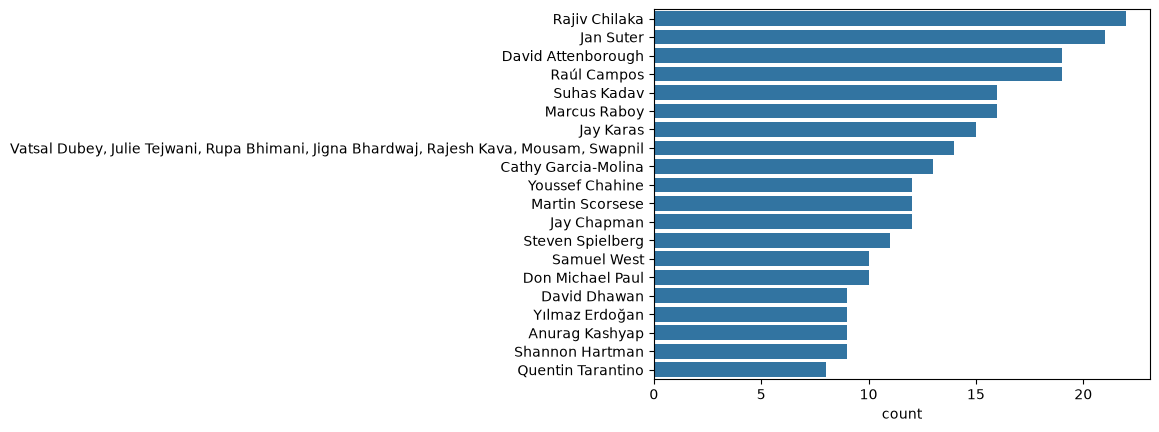

In [286]:
tum_isimler = tum_isimler[
    (tum_isimler != "") &
    (tum_isimler.str.lower() != "unknown")
]

en_cok_adi_gecen=(tum_isimler.value_counts().head(20))
sns.barplot(en_cok_adi_gecen,orient='h')

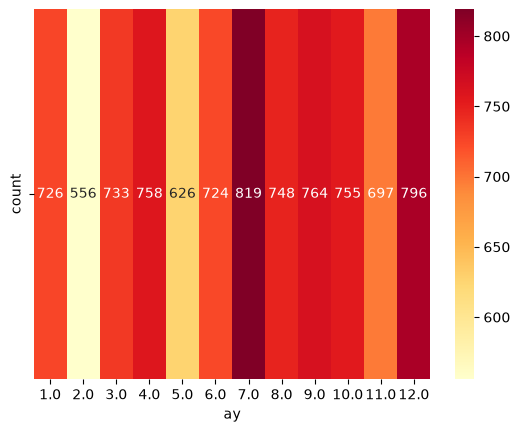

In [305]:
ay_top = df["ay"].value_counts().sort_index().to_frame().T
sns.heatmap(ay_top, annot=True, fmt="d", cmap="YlOrRd")
plt.savefig("content_trend.png", dpi=300, bbox_inches="tight")